In [24]:
% pip install pandas
% pip install numpy
% pip install matplotlib
% pip install scikit-learn
% pip install progress
% pip install scikit-bio
 
% git clone https://github.com/RV2005/archetypes
% pip install "archetypes/"

UsageError: Line magic function `%` not found.


In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

from archetypes import AA
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset
import json

Couldn't import dot_parser, loading of dot files will not be possible.


## Performing AA

In [ ]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"normalized_otu_Norm-sample_type.csv"
# otuFile = r"normalized_otu.csv"

otu = pd.read_csv(otuFile, index_col="sample")
# otu.drop("Unnamed: 0", axis=1, inplace=True)



In [ ]:
FRAC = 1
otu_sample = otu.sample(frac=FRAC)

In [ ]:
otu_log = otu_sample.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

In [ ]:
# from archetypes.numpy._aa_3 import AA_3
from archetypes import AA

AA_data = otu_log.to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 5
aa = AA(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)

print(aa.archetypes_)

[[3.57618913e-07 1.34697103e+00 1.31476442e-01 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.57650304e-07 1.11969198e-01 2.25303776e-04 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.04199175e+00 7.88235532e+00 1.50477665e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.58503305e-07 8.15965159e-02 7.35154486e-07 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.57625148e-07 3.36625456e+00 2.08700717e-02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


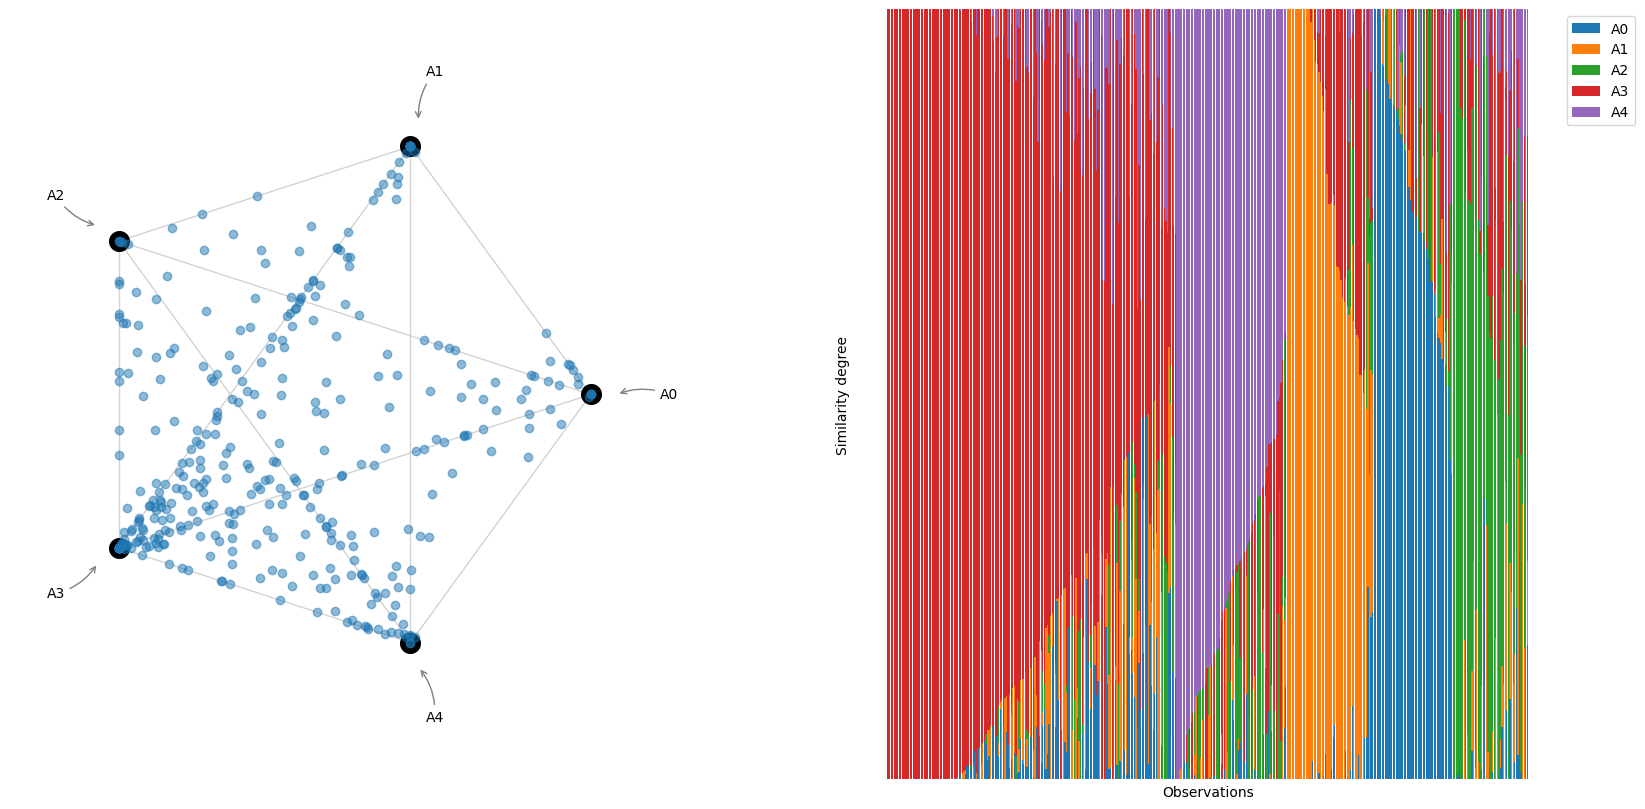

In [ ]:
data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

similarity_degree_permuted, _ = permute_dataset(aa.similarity_degree_, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


In [ ]:
# Make a json file containing all details for the archetypes
import json
aa_dict = {
    "archetypes": aa.archetypes_.tolist(),
    "similarity_degree": aa.similarity_degree_.tolist(),
    "labels": aa.labels_.tolist(), 
    "index": otu_log.index.tolist(),
    "columns": [f"Archetype {i+1}" for i in range(N_ARCHETYPES)], 
    "loss": aa.loss_,
    "info_perms": info["perms"][0].tolist(),
    "info_scores": info["scores"][0].tolist(),
    "info_alphas": info["alphas"][0].tolist(),
}


In [ ]:
methodName = method if isinstance(method, str) else "jensenshannon"

outName = f"otu_AA_{FRAC}_{group}_{methodName}.json"
outPath = os.path.join(outDir, outName)

json.dump(aa_dict, open(outPath, "w"))
# otu_aa.to_csv(outPath, sep="\t")

In [ ]:
json.dump(aa_dict, open("otu_AA_K5_norm_sample_type2.json", "w"))

## Standard Analysis

### Simplex Plotter Utility

In [11]:
### Simplex Plotter
from matplotlib.patches import Patch

def filter_further(data, further_filter, filter_type): 
    if filter_type == "equals": 
        return data[data.isin(further_filter)]
    elif filter_type == "not_equals":
        return data[~data.isin(further_filter)]
    elif filter_type == "greater_than":
        return data[data > further_filter]
    elif filter_type == "less_than":
        return data[data < further_filter]
    else: 
        return data


def plot_simplex(otu_aa, metadata, filter_cols, 
                cmap_name="tab20", legend_type="discrete", 
                remove_nan=False, further_filter=None, figsize=(15, 15), 
                remove_values=[], alpha=0.5, s=5, ax=None, legend_fontsize=12,
                verbose=False, **kwargs):
    """ 
    otu_aa: DataFrame
        The archetypal analysis data
    metadata: DataFrame
        The metadata
    filter_cols: list
        The columns to filter the data by (must contain exact column names from metadata)
    cmap_name: str (optional)
        The name of the colormap to use
    legend_type: str (optional)
        The type of legend to use. Can be "discrete" or "continuous"
    remove_nan: bool (optional)
        Whether to remove NaN values from the data
    further_filter: Dict (optional) = {"filter_type": "equals", "value": []}
        Further filter the data by the values in this list
    figsize: tuple (optional)
        The size of the figure
    """

    present_idx = otu_aa.index.intersection(metadata.index)
    present_points = otu_aa.loc[present_idx]

    # Print the number of values dropped
    if verbose:
        print(f"Dropped {len(otu_aa) - len(present_points)} data points: Index not found in metadata")

    # For each data point, add the first non-null value from filter_cols to the filter_labels
    filter_labels = pd.Series(index=present_points.index, dtype=str)
    for col in filter_cols:
        filter_labels = filter_labels.fillna(metadata.loc[present_idx, col])

    # If further_filter is not none, filter the dataset by matching values to each further_filter element
    if further_filter is not None:
        present_points = filter_further(present_points, further_filter["filter_type"], further_filter["value"])
        filter_labels = filter_further(filter_labels, further_filter["filter_type"], further_filter["value"])

    if remove_nan:
        nan_idx = filter_labels.index[filter_labels.isnull()]
        present_points = present_points.drop(nan_idx)
        filter_labels = filter_labels.drop(nan_idx)

    if(len(remove_values) > 0):
        for col, value in remove_values.items():
            rem_idx = filter_labels.index[filter_labels == value]
            present_points = present_points.drop(rem_idx)
            filter_labels = filter_labels.drop(rem_idx)


    if(legend_type == "discrete"):
        unique_colors = {c: i for i, c in enumerate(filter_labels.unique())}
        color = filter_labels.map(unique_colors)
    elif(legend_type == "continuous"):
        unique_colors = filter_labels
        color = filter_labels.astype(float)

    cmap = plt.get_cmap(cmap_name, len(unique_colors))

    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        
#     MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
    cmap = plt.get_cmap(cmap_name, len(unique_colors))

    simplex(present_points, alpha=alpha, ax=ax, c=color, cmap = cmap, s=s, vertices_labels=otu_aa.columns, **kwargs)

    def add_discrete_legend(ax, unique_colors, cmap):
        legend_patches = [
            Patch(color=cmap(unique_colors[c]), label=c)
            for c in unique_colors
        ]

        # Add the legend to the plot
        ax.legend(handles=legend_patches, title=filter_cols, loc='upper right', fontsize=legend_fontsize, bbox_to_anchor=(1.2, 1))


    def add_continuous_legend(ax, filter_labels, cmap):
        # Add the legend to the plot with appropriate min and max values
        cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
        cbar.set_label(f"{filter_cols}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )

    if legend_type == "discrete":
        add_discrete_legend(ax, unique_colors, cmap)
    elif legend_type == "continuous":
        add_continuous_legend(ax, filter_labels, cmap)




### Compendium Extraction

In [9]:
PROJECT_DATA_COLS = ['link', 'amplicon', 'avg_length', 'bead_beating', 'kit', 'sample_type','condition', 'subjects', 'notes']
SAMPLE_METADATA_COLS = ['project', 'srr', 'library_strategy', 'library_source', 'pubdate','total_bases', 'instrument', 'geo_loc_name', 'iso', 'region']

def extract_metadata_compendium(index, tags, sample_meta, projects, extract_cols = [], verbose=False):
    
    project_cols = [col for col in extract_cols if col in PROJECT_DATA_COLS]
    sample_cols =  [col for col in extract_cols if col in SAMPLE_METADATA_COLS]
    tags_cols =    [col for col in extract_cols if col not in project_cols and col not in sample_cols]

    metadata = pd.DataFrame(index=index, columns=extract_cols)
    for col in project_cols:
        metadata[col] = metadata.index.map(lambda x: projects.loc[x.split("_")[0], col])
        
    sample_meta["sample"] = sample_meta["project"] + "_" + sample_meta["srr"]
    sample_meta.set_index("sample", inplace=True)
    for col in sample_cols:
        metadata[col] = sample_meta[col]
    
    for col in tags_cols:
        col_tags_df = tags[tags["tag"] == col]
        col_tags_df["sample"] = col_tags_df["project"] + "_" + col_tags_df["srr"]
        col_tags_df.set_index("sample", inplace=True)
        metadata[col] = col_tags_df["value"]

    return metadata


### Loading the results
Change the paths below according to your file structure

In [13]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region3k_AdultsOnly\otu_AA_K7_1.0_None_jensenshannon.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)


In [14]:
projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)

tags = pd.read_table("datasets/compendium/tags.tsv")

### Plotting the Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_30568\1701354116.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

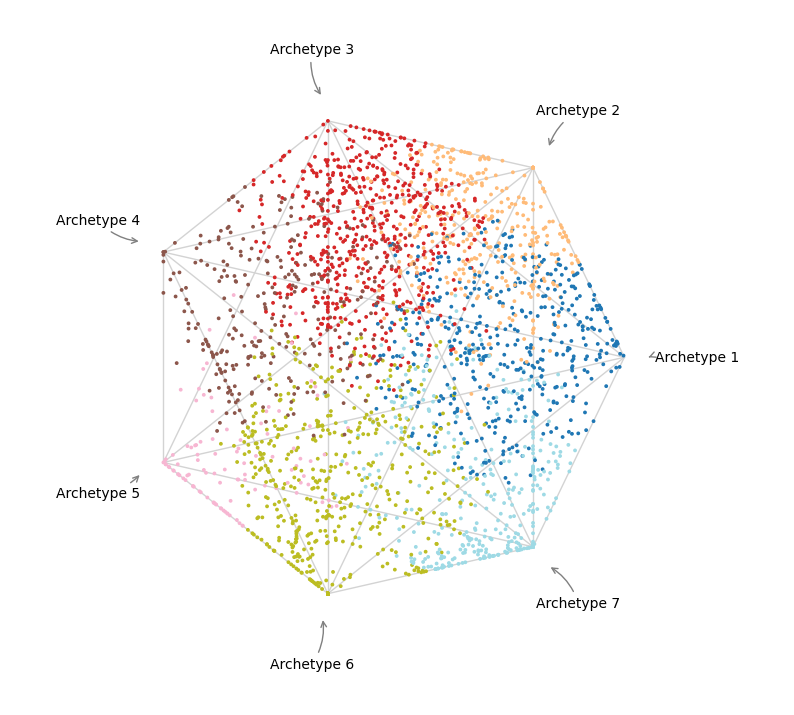

In [15]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=1, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [16]:
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 2", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 7", "Archetype 6", "Archetype 3", "Archetype 9"]]

otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 3", "Archetype 5", "Archetype 6", "Archetype 2" , "Archetype 4"]]

Plotting the reordered Simplex

C:\Users\rayve\AppData\Local\Temp\ipykernel_30568\1370836857.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

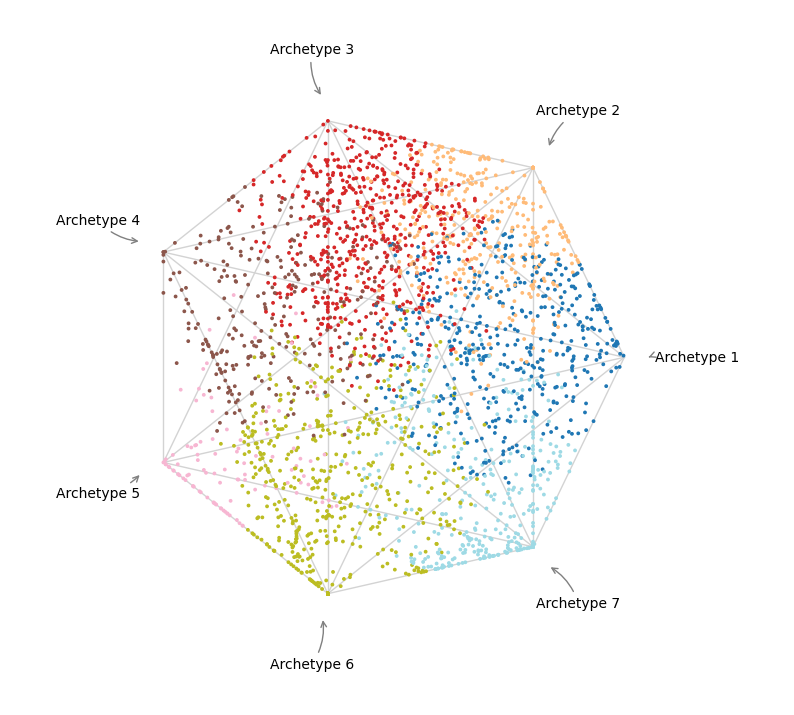

In [17]:
# Normalize the aa_labels

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa_swapped.to_numpy(), alpha=1, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa_swapped.columns)


### Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

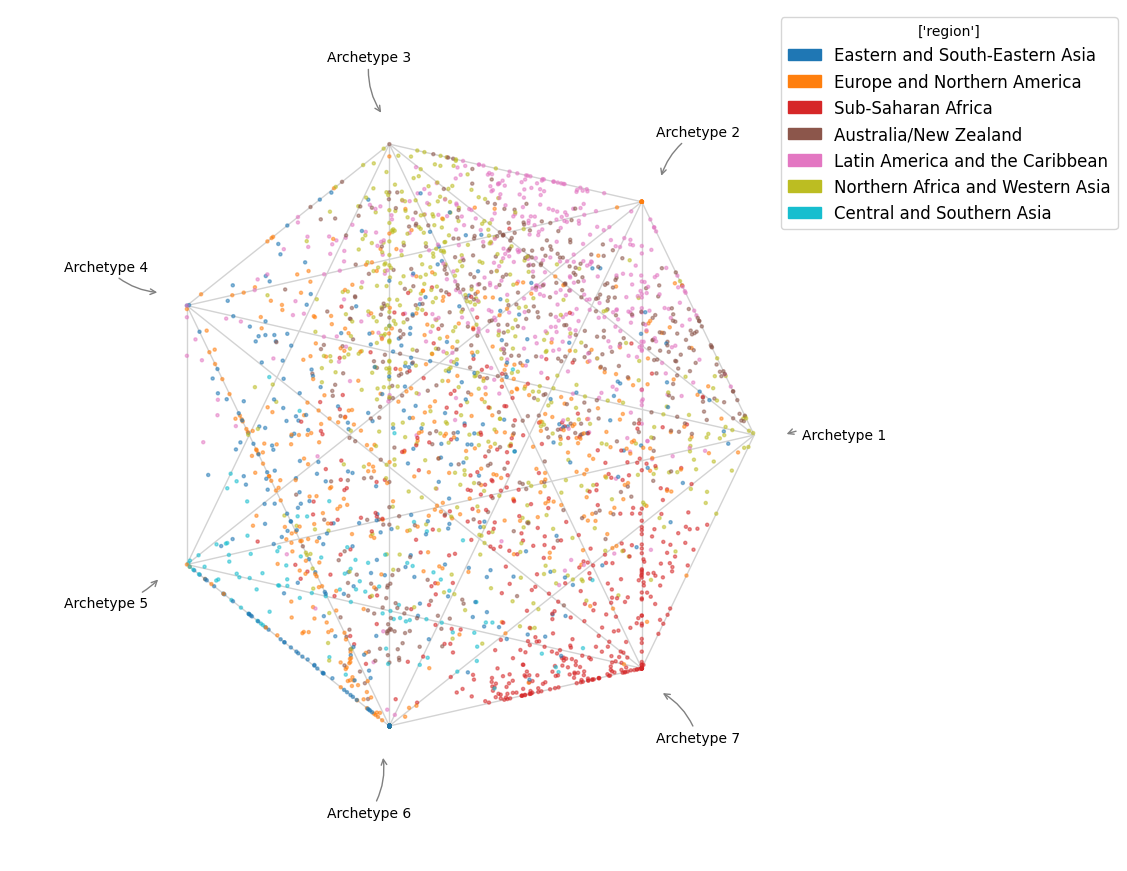

In [18]:
# FOR COUNTRY
filter_cols = ["region"]

metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)
# Remove all samples that are neither "adult" nor "infant" or "child"
# metadata = metadata[metadata["subjects"].isin(["adults", "infants", "children"])]


plot_simplex(otu_aa_swapped, metadata, filter_cols, cmap_name="tab10", legend_type="discrete", remove_nan=True, alpha = 0.5, s=5, remove_values={"region": "unknown"}, figsize=(12, 12))

Similarly, for age. This time, the `legend_type` is "continuous"

In [ ]:
# FOR AGE
filter_cols = ["age_months"]

metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

plot_simplex(otu_aa_swapped, metadata, ["age_months"], "viridis", "continuous", remove_nan=True)

### Group Plotting

100%|██████████| 6/6 [00:04<00:00,  1.26it/s]


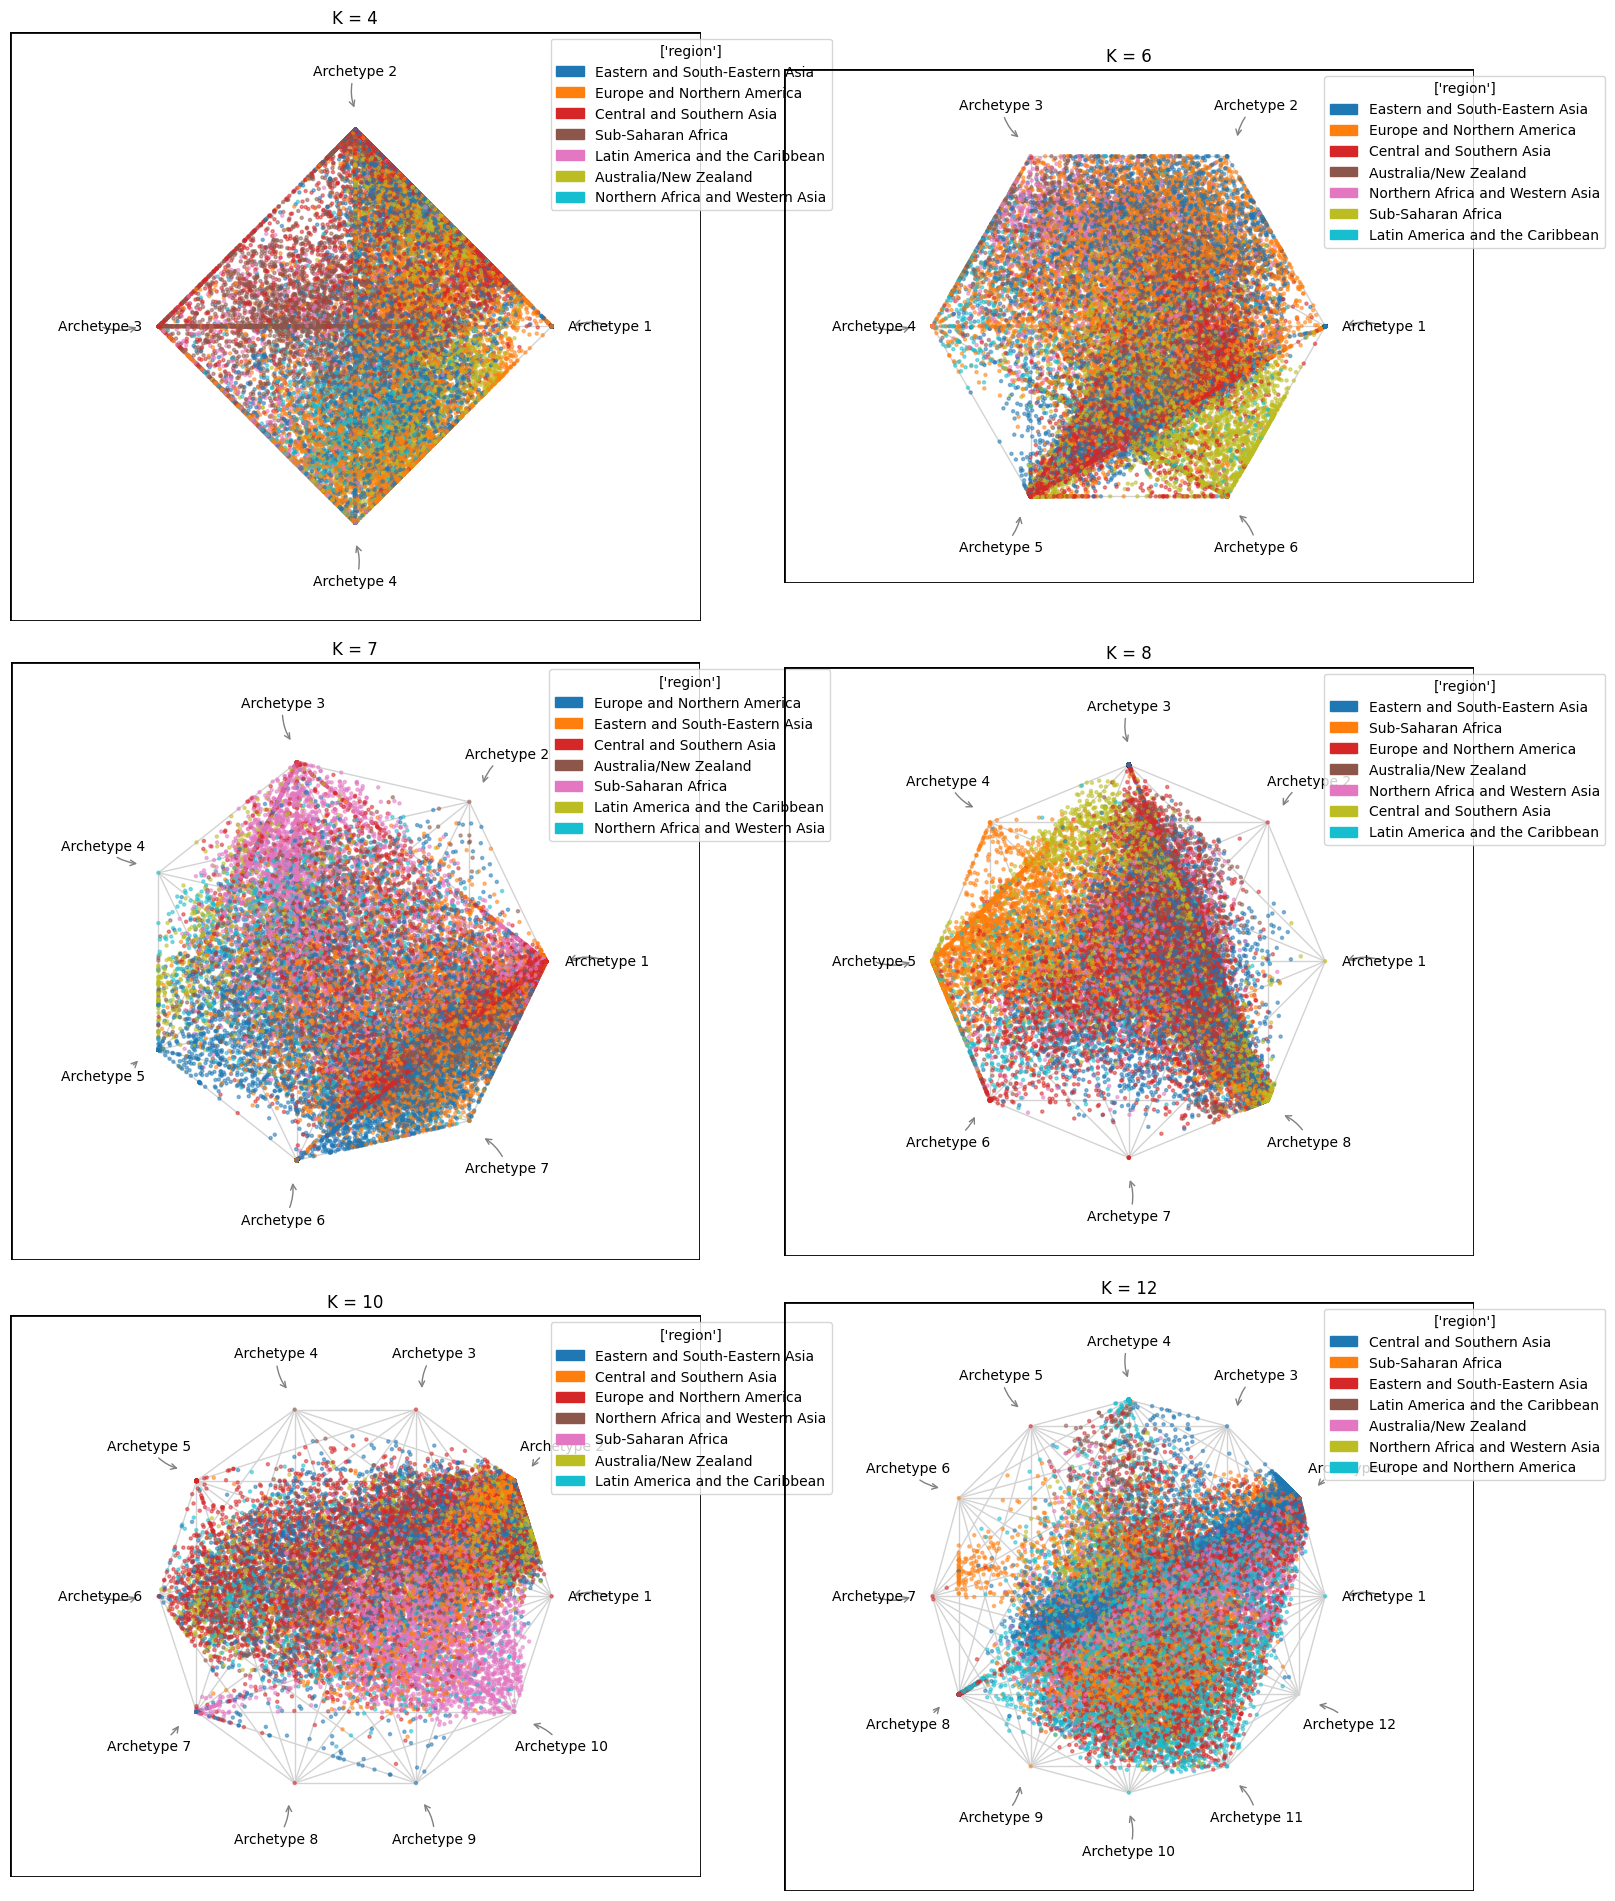

In [105]:
dir = "results/Compendium_N3_N13_NoPC_NoGlom/Norm_pp_100iter-Region30k"
filter_cols = ["region"]

numKs = [4,6,7,8,10,12]

remove_values = {"sample_type": "unknown"}

projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")

# Make subplot for each K
numPlots = len(numKs)
numCols = 2
numRows = int(np.ceil(numPlots / numCols))

plotSize = (8,8)
figSize = (plotSize[0]*numCols, (plotSize[1]*0.8)*numRows)

# Make fig ax with borders
fig, ax = plt.subplots(numRows, numCols, figsize=figSize, tight_layout=True)

for i, k in tqdm(enumerate(numKs), total=numPlots): 
    f = f"otu_AA_K{k}_1.0_None_jensenshannon.json"
    fName = os.path.join(dir, f)
    otu_dict = json.load(open(fName, "r"))
    otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
    aa_labels = np.array(otu_dict["labels"])
    aa_archetypes = otu_dict["archetypes"]
    info = {
        "perms": otu_dict["info_perms"],
    }
    n_archs = len(aa_archetypes)

    metadata = extract_metadata_compendium(otu_aa.index, tags, meta, projects, filter_cols)

    axis = ax[i // numCols, i % numCols] if numPlots > 1 else ax
    plot_simplex(otu_aa, metadata, filter_cols, cmap_name="tab10", legend_type="discrete", remove_nan=True, alpha = 0.5, s=5, remove_values=remove_values, figsize=plotSize, ax = axis, legend_fontsize=10)
    
    axis.set_title(f"K = {k}")
    xlim, ylim = axis.get_xlim(), axis.get_ylim()
    rect = plt.Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0], linewidth=2, edgecolor='black', facecolor='none')
    axis.add_patch(rect)


fig.tight_layout()

## Display Archetype Composition

In [167]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"datasets\compendium\taxonomic_table.csv\raw_taxa_110.csv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_csv(otuFile, index_col="sample")
otu.drop("Unnamed: 0", axis=1, inplace=True)


**Archetype 1**

***Label 1***: Bacteria.Bacteroidota.Bacteroidia.Bacteroidales.Bacteroidaceae.Bacteroides 

***Label 2***: Bacteria.Bacillota.Clostridia.Oscillospirales.Ruminococcaceae.Faecalibacterium 

***Label 3***: Bacteria.Bacillota.Clostridia.Lachnospirales.Lachnospiraceae.Blautia 

***Label 4***: Bacteria.Bacillota.Clostridia.Lachnospirales.Lachnospiraceae.Mediterraneibacter 

***Label 5***: Bacteria.Bacillota.Clostridia.Lachnospirales.Lachnospiraceae.Agathobacter 

***Label 6***: Others 



**Archetype 2**

***Label 1***: Bacteria.Pseudomonadota.Alphaproteobacteria.Rickettsiales.Mitochondria.Incertae Sedis 

***Label 2***: Bacteria.NA.NA.NA.NA.NA 

***Label 3***: Bacteria.Bacteroidota.Bacteroidia.Bacteroidales.Bacteroidaceae.Bacteroides 

***Label 4***: Bacteria.Actinomycetota.Actinobacteria.Propionibacteriales.Propionibacteriaceae.Cutibacterium 

***Label 5***: Bacteria.Bacillota.Bacilli.Lactobacillales.Streptococcaceae.Streptococcus 

***Label 6***: Others 



**Archetype 3*

C:\Users\rayve\AppData\Local\Temp\ipykernel_4860\3278682410.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_4860\3278682410.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_4860\3278682410.py:72: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_4860\3278682410.py:72: UserWarning: set_ticklabels() should only be used with

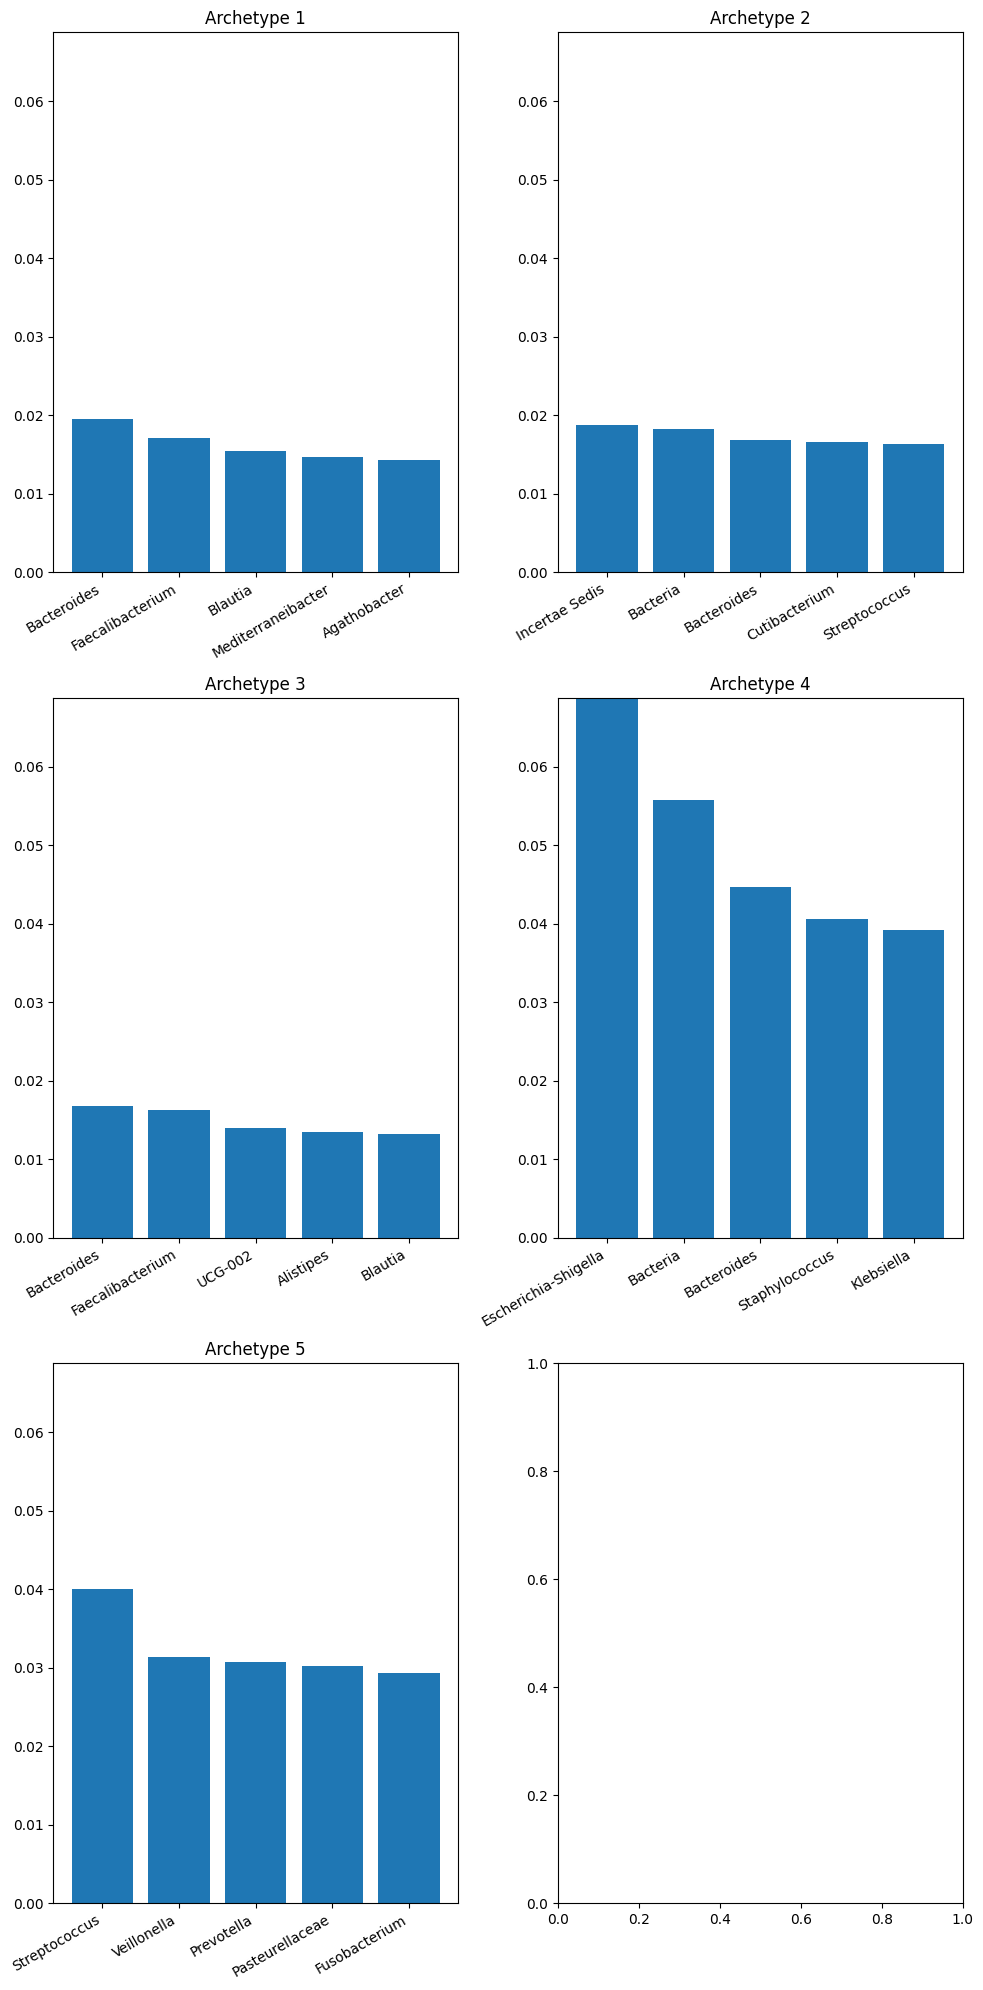

In [168]:
# archs = pd.DataFrame(aa_archetypes, columns=grouped_cols, index=[f"Archetype {i+1}" for i in range(n_archs)])
n_archs = len(aa_archetypes)
archs = pd.DataFrame(aa_archetypes, columns=otu.columns, index=[f"Archetype {i+1}" for i in range(n_archs)])

NUM_TAXA = 5

# Extract the top 5 taxa for each archetype

# For each row in archs, sort the values in descending order

tax_sorted_archs = archs.copy()
for i in range(archs.shape[0]):
    tax_sorted_archs.iloc[i] = tax_sorted_archs.iloc[i].sort_values(ascending=False)

# sorted_archs = archs.apply(lambda x: x.sort_values(ascending=False), axis=0)
top_n_taxa_archs = tax_sorted_archs.iloc[:, :NUM_TAXA]

# Go through each top taxa archetype, and find the column from which the value comes from

top_taxa_archs = [] # 2D Tuples (value, taxa)
for i,arch in top_n_taxa_archs.iterrows():
    top_taxa  = []
    for val in arch:
        # Find the column from which the value comes from in Row i from archs dataframe
        taxa = archs.loc[i][archs.loc[i] == val].index[0]
        top_taxa.append((val, taxa))

    top_taxa_archs.append(top_taxa)


# Find the percentage of each taxon in the archetype w.r.t archs
for i, arch in enumerate(top_taxa_archs):
    total = archs.loc[f"Archetype {i+1}"].sum()
    for j, (val, taxa) in enumerate(arch):
        top_taxa_archs[i][j] = (val/total, taxa)

# For each arch, add a new element ("Others") with the value 1 - sum of all other values
for i, arch in enumerate(top_taxa_archs):
    top_taxa_archs[i].append((1 - sum([val for val, taxa in arch]), "Others"))

# Make similar graphs but for bar plot, make sure to color the bars, and label them with respective index as above
# Set the same y-axis for all bar plots, which is the maximum value of all archetypes in top_taxa_archs

max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))
for i, arch in enumerate(top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa for val, taxa in arch]

    print(f"**Archetype {i+1}**")
    print()
    for k, label in enumerate(labels):
        print(f"***Label {k+1}***: {label} \n")
    print("\n")

    plotLabels = []
    for k, label in enumerate(labels[:-1]):
        curr = label.split(".")[0]
        for t in label.split("."):
            if(t == "NA"):
                break
            curr = t
        plotLabels.append(curr)
    
    plotLabels += ["Others"]


    ax[i // 2, i % 2].bar(plotLabels[:-1], vals[:-1])
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")
    ax[i // 2, i % 2].set_ylim(0, max_val)
    ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()



### Automated Blast

In [ ]:
import xml.etree.ElementTree as ET

def parseBlastXml(source): 

    taxa_hits = {}

    # tree = ET.parse(ET.fromstring(source))
    root = ET.fromstring(source)

    # Find all the hits, store them in a list of dictionaries, include sub children as well
    hits = []
    for iteration in root.findall(".//Iteration"):
        taxa_hits[iteration.find("Iteration_query-def").text] = []

        for hit in iteration.findall(".//Iteration_hits/Hit"):
            hit_dict = {}
            for child in hit:
                try: 
                    hit_dict[child.tag] = float(child.text) 
                except:
                    hit_dict[child.tag] = child.text
                if(child.tag == "Hit_hsps"):
                    hit_dict["Hsps"] = {}
                    hsps = child.findall(".//Hsp")[0].findall("./")
                    for hsp in hsps:
                        try: 
                            hit_dict["Hsps"][hsp.tag] = float(hsp.text)
                        except ValueError as e:
                            hit_dict["Hsps"][hsp.tag] = hsp.text

            taxa_hits[iteration.find("Iteration_query-def").text].append(hit_dict)


    return taxa_hits

# with open("my_blast.xml", "r") as f:
#     hits = parseBlastXml(f.read())
#     print(hits)


In [ ]:
# write all the taxa in FASTA format file

def writeFasta(taxa, outPath):
    # Create the file if not exists
    with open(outPath, "a") as out_stream:
        out_stream.write(f">{taxa}\n")
        out_stream.write(f"{taxa}\n")

for arch in top_taxa_archs:
    for val, taxa in arch:
        if taxa == "Others":
            continue
        writeFasta(taxa, f"temp.fasta")


In [ ]:
from Bio import Blast

with open ("temp.fasta", "r") as in_stream:
    src = in_stream.read()

result_stream = Blast.qblast("blastn", "ref_prok_rep_genomes", src)

with open("my_blast.xml", "wb") as out_stream:
    out_stream.write(result_stream.read())

result_stream.close()

In [ ]:
with open("my_blast.xml", "r") as f:
    taxa_hits = parseBlastXml(f.read())

NUM_HITS = 3
filtered_hits = {}

for taxa, hits in taxa_hits.items():
    sorted_hits = sorted(hits, key=lambda x: x["Hsps"]["Hsp_evalue"])
    filtered_hits[taxa] = sorted_hits[:NUM_HITS]



C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used 

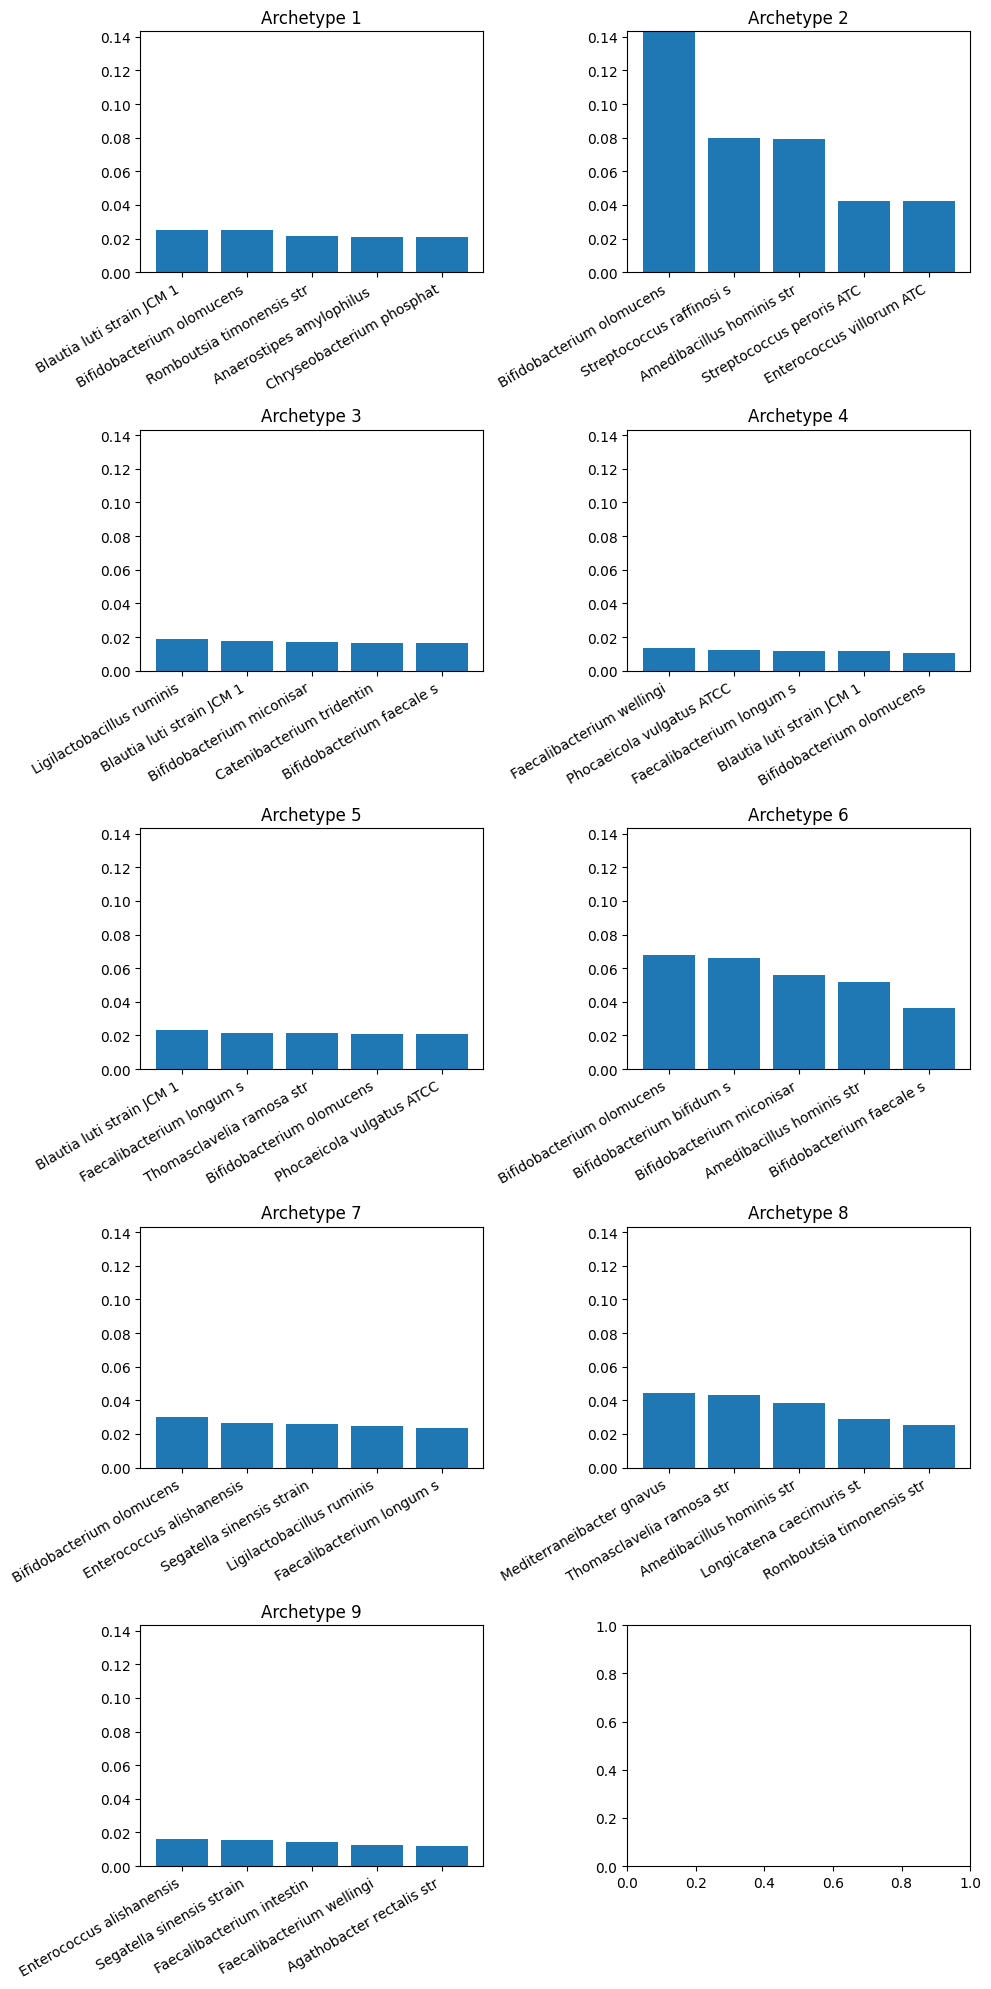

In [ ]:
max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))

labelled_top_taxa_archs = []


# Take top taxa archs and copy it into labelled_top_taxa_archs using loops
for i, arch in enumerate(top_taxa_archs):
    labelled_top_taxa_archs.append([])
    for val, taxa in arch:
        if taxa == "Others":
            labelled_top_taxa_archs[i].append([val, taxa])
            continue
        labelled_top_taxa_archs[i].append((val, filtered_hits[taxa]))


MAX_LABEL_LEN = 25

# I wanna kill myself this is so shit ohmygod TODO FIX
for i, arch in enumerate(labelled_top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa[0]["Hit_def"][:MAX_LABEL_LEN] for val, taxa in arch[:-1]]
    labels.append("Others")
    # print(labels[0]["Hit_def"])
    # print(f"**Archetype {i+1}**")
    # print()
    # for k, label in enumerate(labels):
    #     print(f"***Label {k+1}***: {label} \n")
    # print("\n")
    plotLabels = [f"{i+0}" for i in range(len(labels)-1)] + ["Others"]
    ax[i // 2, i % 2].bar(labels[:-1], vals[:-1])
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")
    ax[i // 2, i % 2].set_ylim(0, max_val)
    ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()



### Loss Analysis

(6804, 3)
(6804, 4)
(6804, 5)
(6804, 6)
(6804, 7)
(6804, 8)
(6804, 9)
(6804, 10)
(6804, 11)
(6804, 12)
(6804, 14)
(6804, 15)
Arch 3: 9041982.35808466
Arch 4: 8364947.517900469
Arch 5: 8038953.363329947
Arch 6: 7760861.96238741
Arch 7: 7586226.945857908
Arch 8: 24848519.011912197
Arch 9: 21727791.36283116
Arch 10: 7179510.964153438
Arch 11: 7908469.64364399
Arch 12: 6992430.739905717
Arch 14: 21024155.236029185
Arch 15: 6825115.617798014


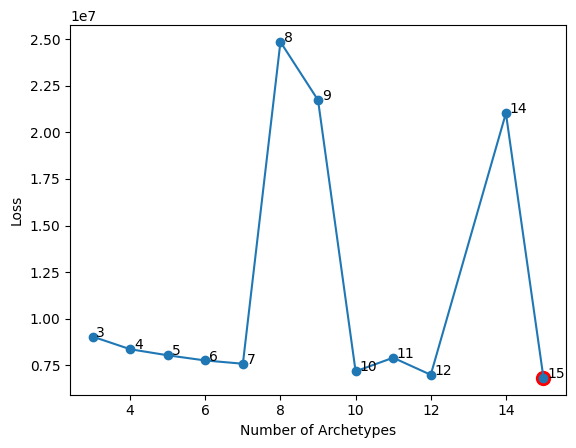

In [39]:
# Read all json files from /results/SBATCH_N3_N12, and plot the loss vs n_archetypes
import glob
import json

jsonFiles = glob.glob(r"results\Compendium_N3_N13_NoPC_NoGlom\Norm-Region\*.json")

losses = []

nIdx_archs = [3,4,5,6,7,8,9,10,11,12,14,15]


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in nIdx_archs:
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
            print(otu_aa.shape)
            arch_losses[n] = otu_dict["loss"][-1]    


plt.plot(arch_losses.keys(), arch_losses.values(), marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Loss")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(nIdx_archs):
    print(f"Arch {txt}: {arch_losses[txt]}")
    plt.annotate(f"{txt}", (nIdx_archs[i] + pad, arch_losses[txt] + pad))

# Plot the smallest loss in green
min_loss = min(arch_losses.values())
min_key = [key for key, value in arch_losses.items() if value == min_loss][0]
plt.scatter(min_key, min_loss, color="red", s=100)

plt.show()



### PCoA Comparison

In [ ]:
otuFile = r"datasets\compendium\normalized\normalized_otu_Norm-sample_type.csv"

otu = pd.read_csv(otuFile, index_col="sample")

In [ ]:
pcoa_data = otu.copy()
pcoa_data = pcoa_data.map(lambda x: np.log2(x+1))

In [ ]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

method = scipy.spatial.distance.jensenshannon  #'jensenshannon' # or "jensenshannon", unifrac is problematic
bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA
pcoa_results = pcoa(bdiv, number_of_dimensions=7)

# Extract the coordinates
pcoa_coordinates = pcoa_results.samples

C:\Users\rayve\AppData\Local\Temp\ipykernel_27276\1098488126.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  add_discrete_legend(plt.gca(), unique_colors, plt.cm.get_cmap("tab20", len(unique_colors)))
C:\Users\rayve\AppData\Local\Temp\ipykernel_27276\1098488126.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_27276\1098488126.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with Dat

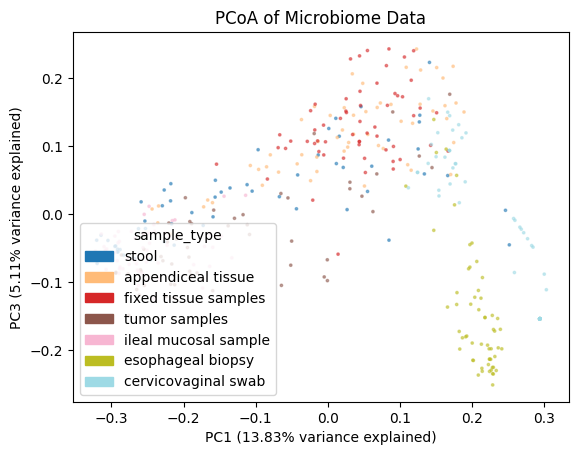

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.cm as cm

def add_discrete_legend(ax, unique_colors, cmap):
    legend_patches = [
        Patch(color=cmap(unique_colors[c]), label=c)
        for c in unique_colors
    ]
    # Add the legend to the plot
    ax.legend(handles=legend_patches, title=filter_col, loc='lower left')

def add_continuous_legend(ax, filter_labels, cmap):
    # Add the legend to the plot with appropriate min and max values
    cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
    cbar.set_label(f"{filter_col}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )



filter_col = "sample_type"
legend_type = "discrete" # or "continuous"

# Create color list for according to filter_col
metadata = extract_metadata_compendium(pcoa_coordinates.index, tags, meta, projects, [filter_col])
filter_labels = pd.Series(index=pcoa_coordinates.index, dtype=str)

for col in [filter_col]:
    filter_labels = filter_labels.fillna(metadata.loc[pcoa_coordinates.index, col])

if(legend_type == "discrete"):
    unique_colors = {c: i for i, c in enumerate(filter_labels.unique())}
    color = filter_labels.map(unique_colors)
elif(legend_type == "continuous"):
    unique_colors = filter_labels
    color = filter_labels.astype(float)



# Create a scatter plot
plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC3'], s=3, c=color, cmap="tab20", alpha=0.5)


if legend_type == "continuous":
    plt.colorbar(label=filter_col)
else:
    add_discrete_legend(plt.gca(), unique_colors, plt.cm.get_cmap("tab20", len(unique_colors)))
    

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC3 ({pcoa_results.proportion_explained[2]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

# # Add sample labels if desired
# for idx, row in pcoa_coordinates.iterrows():
#     plt.annotate(idx, (row['PC1'], row['PC2']))

plt.show()



## Compendium Dataset Format Manipulation

### Data Normalization

In [ ]:
otuFile = r"datasets\compendium\taxonomic_table.csv\raw_taxa_110.csv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_csv(otuFile, index_col="sample")
otu.drop("Unnamed: 0", axis=1, inplace=True)

In [ ]:
projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
meta["sample"] = meta["project"] + "_" + meta["srr"]
meta.set_index("sample", inplace=True)

tags = pd.read_table("datasets/compendium/tags.tsv")

In [ ]:
def normalize_data(control, normalize, otu, meta, tags, projects, saveDir =None, ignore_zero=True, ignore = [], tol=0, verbose=False): 
    columns_of_interest = list(control.keys()) + list(normalize.keys())
    filtered_df = extract_metadata_compendium(meta.index, tags, meta, projects, columns_of_interest)

    for label, values in control.items():
        if values is None:
            values = filtered_df[label].unique()
            values = values[~pd.isnull(values)]
            
        filtered_df = filtered_df[filtered_df[label].isin(values)]
    
    ignored = 0
    normalized_df = pd.DataFrame()
    min_counts = np.inf
    min_val = ""
    for label, value in normalize.items():
        if value is None:
            value = filtered_df[label].unique()
            value = value[~pd.isnull(value)]
            
        for val in value:
            values = filtered_df[filtered_df[label] == val]
            if ignore_zero and len(values) == 0:
                print(f"Value {val} not found in {label}. Ignoring")
                ignored += 1
                continue
            if val in ignore:
                ignored += 1
                print(f"Value {val} ignored")
                continue
            
            if len(values) < min_counts:
                min_counts = len(values)
                min_val = val

    print(f"Minimum counts: {min_counts} for value {min_val} in {label}")

    for label, value in normalize.items():
        if value is None:
            value = filtered_df[label].unique()
            value = value[~pd.isnull(value)]
            
        for val in value:
            values = filtered_df[filtered_df[label] == val]
            if ignore_zero and len(values) == 0:
                continue
            if val in ignore:
                continue
            sam_num = int(min(len(values), min_counts*(1+tol)))
            normalized_df = pd.concat([normalized_df, values.sample(sam_num)])
        
    print(f"Ignored {ignored} values")
    
    print()

    normalized_idx = normalized_df.index
    normalized_otu = otu.loc[normalized_idx]

    if saveDir:
        name = "compendium_Norm-" + "_".join(normalize.keys()) + ".csv"
        normalized_otu.to_csv(os.path.join(saveDir, name))
        print(f"Saved normalized data to {name}")
    
    if verbose: 
        # Count the number of samples for each label, store in a df and print
        counts = {}
        for label, value in normalize.items():
            if value is None:
                value = filtered_df[label].unique()
                value = value[~pd.isnull(value)]
            counts[label] = {}
            for val in value:
                values = normalized_df[normalized_df[label] == val]
                counts[label][val] = len(values)
        counts_df = pd.DataFrame(counts)
        print(counts_df)
        print()
        print("Normalized Data shape: ", normalized_otu.shape)
        
    return normalized_otu, normalized_df

In [ ]:
# subjects: healthy adult samples
subjects_NoCondition_Adults_only = ['cenenarians & relatives', 'adults aged above 40', 'adults', 'adults and elderly', 'elderly', 'healthy adults', 'girls and women', 'adolescents', 'women', 'healthy women', 'females', 'healthy humans', 'healthy donors', 'healthy individuals', 'healthy chinese ages 3-100+', 'all ages', 'healthy western individuals', 'Chinese adults (18-65)', 'Indian families', 'Finnish adult men', 'long-living group (> 90 yr), elderly, young aduls']

# subjects: healthy, no condition, infant and children samples: 
subjects_NoCondition_Children_only = ['younger than 2', 'infants', 'children', 'infants and children', 'young children', 'babies', 'female infant', 'infants and toddlers', 'Children']

# subjects: healthy, no condition, mixed samples:
subjects_NoCondition_mixed = ['children and adults', 'adults + children', 'infants, children and adults', 'infants and adults', 'children and adolscents', 'children and adolescents', 'childrena and adolescents',]

# condition: top 9 occurring conditions(over 1800 samples)
condition_top9_occuring = ['allogeneic hematopoietic cell transplantation','preterm','CD','allo-HCT','IBD','colorectal cancer','asthma','malnutrition + healthy','HIV']

In [ ]:
# Normalize by condition

control = {"sample_type": ["stool"]}
normalize = {"condition": condition_top9_occuring}
ignore = ["unknown"]
saveDir = r"datasets/compendium/normalized"
norm_otu, norm_meta = normalize_data(control, normalize, otu, meta, tags, projects, saveDir=saveDir, ignore=ignore)


In [ ]:
newMeta = extract_metadata_compendium(otu.index, tags, meta, projects, ["subjects", "region", "condition", "sample_type"])

newMeta = newMeta[newMeta["condition"] == "healthy"]
newMeta = newMeta[newMeta["subjects"].isin(subjects_NoCondition_Adults_only)]
newMeta = newMeta[newMeta["region"] == "Europe and Northern America"] 

print(newMeta.shape)
# Count the number of samples for each region in newMeta
counts = newMeta["sample_type"].value_counts()
print(counts)

(17652, 4)
sample_type
stool                              14055
blood and stool                     1069
oral swab, stool, skin swab          864
stool, saliva                        731
stool and rectal swabs               457
SHIME synthetic colon                181
stool, saliva, skin                   84
stool and sigmoid brush samples       80
Name: count, dtype: int64


In [ ]:
# Normalize by region
control = {"sample_type": ["stool"], "condition": ["healthy"], "subjects": subjects_NoCondition_Children_only}
normalize = {"region": None}
ignore = ["unknown", "Oceania", "Latin America and the Caribbean"]
tol = 0
saveDir = r"datasets/compendium/normalized"
norm_otu, norm_meta = normalize_data(control, normalize, otu, meta, tags, projects, saveDir=saveDir, ignore=ignore, verbose=True, tol=tol)


Value unknown ignored
Value Latin America and the Caribbean ignored
Minimum counts: 616 for value Central and Southern Asia in region
Ignored 2 values

Saved normalized data to compendium_Norm-region.csv
                                 region
Eastern and South-Eastern Asia      616
Europe and Northern America         616
unknown                               0
Central and Southern Asia           616
Australia/New Zealand               616
Latin America and the Caribbean       0

Normalized Data shape:  (2464, 4680)


In [ ]:
extract_metadata_compendium(norm_otu.index, tags, meta, projects, ["sample_type", "region"])

,sample_type,region
sample,,
PRJDB11894_DRR304690,stool,Eastern and South-Eastern Asia
PRJNA396815_SRR6867663,stool,Eastern and South-Eastern Asia
PRJNA437504_SRR6820050,stool,Eastern and South-Eastern Asia
PRJDB9469_DRR242412,stool,Eastern and South-Eastern Asia
PRJDB11894_DRR304691,stool,Eastern and South-Eastern Asia
...,...,...
PRJEB38948_ERR4346775,stool,Central and Southern Asia
PRJEB38948_ERR4347771,stool,Central and Southern Asia
PRJEB6358_ERR520696,stool,Central and Southern Asia


### Getting Project file stats

In [ ]:
# For each region, find the most common project that the samples come from 

def find_most_common_project(otu, meta, tags, projects, filter):
    col = filter.keys()[0]
    val = filter.values()[0]
    # Get the samples from the region
    filtered_df = extract_metadata_compendium(otu.index, tags, meta, projects, ["project", col])
    filtered_df = filtered_df[filtered_df[col] == val]
    filtered_otu = otu.loc[filtered_df.index]

    # Get the projects for the samples
    projects = projects.index
    project_counts = {}
    for project in projects:
        project_counts[project] = len(filtered_df[filtered_df["project"] == project])
    
    # Sort the projects by count
    sorted_projects = sorted(project_counts.items(), key=lambda x: x[1], reverse=True)
    
    return sorted_projects

# Find the most common project for each region
regions = meta["sample_type"].unique()
region_projects = {}
for region in regions:
    region_projects[region] = find_most_common_project(otu, meta, tags, projects, region)[:5]
    print(f"Region: {region}")
    print(region_projects[region])


AttributeError: 'str' object has no attribute 'keys'

In [ ]:
def extract_relevant_projects(projects, filter, ignore={}):
    main_col = list(filter.keys())[0]

    filtered_projects = projects.copy()

    # Remove projects in the ignore list
    for key, values in ignore.items(): 
        filtered_projects = filtered_projects[~filtered_projects[key].isin(values)]
    # Removing nan and empty values
    filtered_projects = filtered_projects[filtered_projects[main_col] != ""]
    filtered_projects = filtered_projects[~filtered_projects[main_col].isnull()]

    # Filter out projects which match the filter
    for key, values in filter.items():
        if values is not None:
            filtered_projects = filtered_projects[filtered_projects[key].isin(values)]

    filtered_projects.reset_index(drop=False, inplace=True)

    # Generate Summary DF
    filtered_projects_summary = pd.DataFrame(index=filtered_projects[main_col].unique(), columns=["projects", "num_projects", "num_samples"])
    
    # Group all projects with the same condition
    filtered_projects_summary["projects"] = filtered_projects.groupby(main_col)["project"].apply(lambda x: x.unique())
    filtered_projects_summary["num_projects"] = filtered_projects_summary["projects"].map(lambda x: len(x))
    
    # Count the number of samples in each project
    filtered_projects_summary["num_samples"] = filtered_projects_summary["projects"].map(lambda x: sum([len(otu[otu.index.str.contains(p)]) for p in x]))

    filtered_projects_summary.sort_values("num_samples", ascending=False, inplace=True)

    return filtered_projects_summary


In [ ]:
filter = {"sample_type": None, "subjects": subjects_NoCondition_Adults_only, "condition": ["healthy"]}
ignore = {"condition": ["healthy"]}
filtered_projects_summary = extract_relevant_projects(projects, filter, {})
filtered_projects_summary

,projects,num_projects,num_samples
stool,"[PRJDB11894, PRJDB8511, PRJDB10527, PRJDB10612...",66,25103
blood and stool,"[PRJNA678221, PRJNA743361]",2,1069
"oral swab, stool, skin swab",[PRJEB5729],1,864
"stool, saliva","[PRJEB6518, PRJNA421288]",2,731
stool and rectal swabs,[PRJNA528754],1,457
SHIME synthetic colon,[PRJNA422125],1,181
"stool, saliva, skin",[PRJEB42056],1,84
stool and sigmoid brush samples,[PRJNA401981],1,80


In [ ]:
sum([len(row["projects"]) for i, row in filtered_projects_summary[:10].iterrows() if row["num_samples"] > 0])

221

## Stacked Bar New

In [12]:
def stacked_bar(
    points,
    perms,
    ax=None,
    labels=None,
    vertices_labels=None,
    cmap_name="tab20",
    pad = 0.03,
    **kwargs,
):
    if not ax:
        ax = plt.gca()

    points = np.asarray(points)
    perms = np.array([perms])
    points, _ = permute_dataset(points, perms)
    
    m = points.shape[0]
    n = points.shape[1]

    if vertices_labels is None:
        vertices_labels = [f"A{i}" for i in range(n)]

    if labels is None:
        show_labels = False
        labels = np.arange(m)
    else:
        show_labels = True


    if show_labels:
        # Group all the points by their labels
        label_groups = {}
        labels, idx = np.unique(labels, return_inverse=True)
        idx = permute_dataset(idx, perms)[0]
        for i in range(len(labels)):
            label_groups[labels[i]] = points[idx == i] 

        x_centers = np.asarray([len(label_groups[label]) for label in labels])
        x_centers = np.cumsum(x_centers) - x_centers // 2  
        group_padding = pad * len(points)

        # Create a colormap for the vertice_labels
        cmap = plt.get_cmap(cmap_name, len(vertices_labels))
        colors = [cmap(i) for i in range(len(vertices_labels))]

        # Add the labels to the x-axis
        for i, label in enumerate(labels):
            grp_points = label_groups[label]
            n_points = len(grp_points)

            bar_x = np.arange(n_points) + x_centers[i] - n_points // 2 + group_padding*i

            bottom = np.zeros(n_points)
            for j, vertice_label in enumerate(vertices_labels):
                ax.bar(bar_x, grp_points[:, j], color=colors[j], bottom=bottom, **kwargs)
                bottom += grp_points[:, j]

            ax.bar(np.arange(bar_x[-1], bar_x[-1] + group_padding), 0, color=colors[j], **kwargs)

            ax.text(x_centers[i] + group_padding*i, -0.05, label, ha="center", va="top", fontsize=8, rotation=90)

        # Create a legend for the vertices
        legend_patches = [
            Patch(color=colors[i], label=vertices_labels[i]) for i in range(len(vertices_labels))
        ]
        ax.legend(handles=legend_patches, loc="upper left", bbox_to_anchor=(1, 1))
        
        ax.set_xticks([])
        ax.set_xticklabels([])


    else: 
        # Plot the points
        bottom = np.zeros(m)
        for j, vertice_label in enumerate(vertices_labels):
            ax.bar(labels, points[:, j], label=vertice_label, bottom=bottom, **kwargs)
            bottom += points[:, j]

        ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

    # Set the labels
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)

    ax.set_ylabel("Similarity degree")
    # ax.set_xlabel("Observations")
    ax.set_yticks([])
    ax.set_yticklabels([])
    if not show_labels:
        ax.set_xticks([])
        ax.set_xticklabels([])

    # set axis limits
    ax.axis("on")
    ax.autoscale()

    return ax


<Axes: ylabel='Similarity degree'>

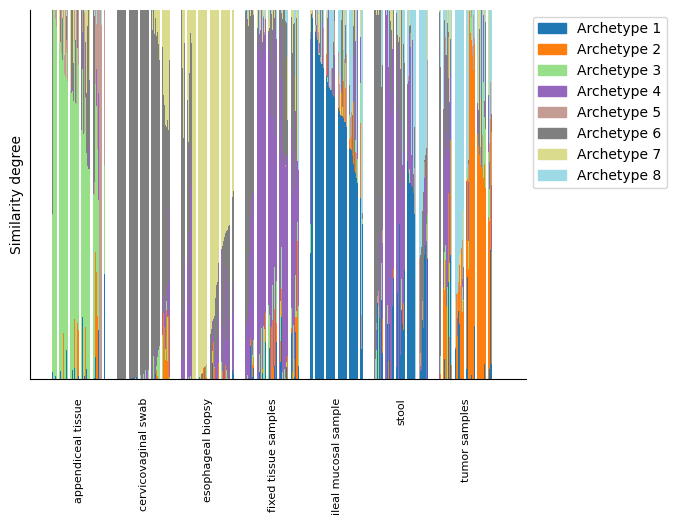

In [13]:
vertices_labels = [f"Archetype {i+1}" for i in range(n_archs)]
filter_cols = ["sample_type"]
metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

labels = metadata["sample_type"].to_numpy()

stacked_bar(otu_aa.to_numpy(), vertices_labels=vertices_labels, labels=labels, perms= info["perms"])


Dropped 0 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_31464\3929728801.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


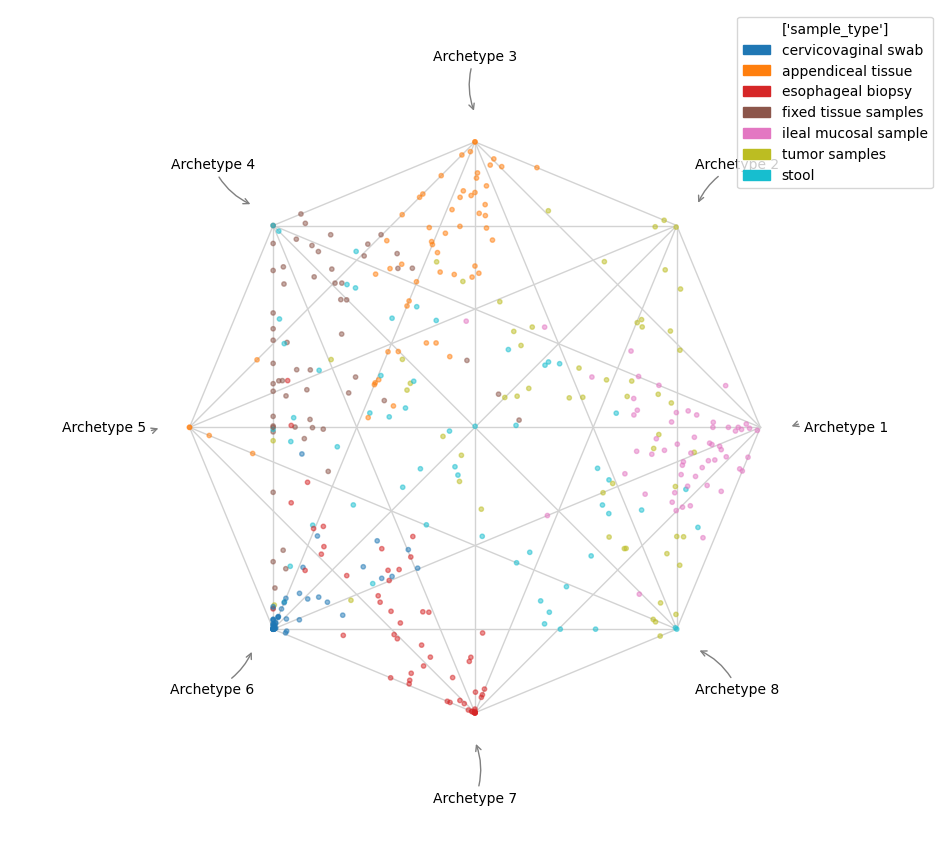

In [14]:
plot_simplex(otu_aa, metadata, ["sample_type"], cmap_name="tab10", legend_type="discrete", remove_nan=True, alpha = 0.5, s=10, remove_values={"region": "unknown"}, figsize=(12, 12))

## Num Archs Analysis

In [26]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm-Region\otu_AA_K6_1.0_None_jensenshannon.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)




In [264]:
otuFile = r"datasets\compendium\normalized\compendium_Norm-sample_type.csv"
otu = pd.read_csv(otuFile, index_col="sample")

X = otu.copy()
X = X.map(lambda x: np.log2(x+1)).to_numpy()

In [ ]:
def calc_vaa_2(X_orig, archetypes, archetype_weights):
    """
    Calculate the VAA value for the given data.
    X: numpy array of shape (N, M)
    n_archs: number of archetypes
    """

    X = X_orig
    n = X.shape[0]
    N = X.shape[1]

    V = np.matrix(archetypes)
    U = np.matrix(archetype_weights)
    P = U @ V

    del_sq = 1.0/(N*n) * np.linalg.norm(X - P, ord="fro")**2

    c = V.shape[0]
    effic_PX = np.trace(np.cov(P) @ np.linalg.inv(np.cov(X)))
    cpx = 2*(2*c-1)/effic_PX
    vaa = np.log(del_sq) + cpx
    return vaa



In [55]:
otuFile = r"datasets\compendium\normalized\compendium_Norm-region7k.csv"
otu = pd.read_csv(otuFile, index_col="sample")

X = otu.copy()
X = X.map(lambda x: np.log2(x+1)).to_numpy()

Calculating Vaa for K= 3
Vaa for K=3: -0.6604021590228127
Calculating Vaa for K= 4
Vaa for K=4: -0.627019683959768
Calculating Vaa for K= 5
Vaa for K=5: -0.6214229043277746
Calculating Vaa for K= 6
Vaa for K=6: -0.6081978720936797
Calculating Vaa for K= 7
Vaa for K=7: -0.5986720944355177
Calculating Vaa for K= 8
Vaa for K=8: 0.015201305833819066
Calculating Vaa for K= 9
Vaa for K=9: -0.09149205981868144
Calculating Vaa for K= 10
Vaa for K=10: -0.5964583354370455
Calculating Vaa for K= 11
Vaa for K=11: -0.623924280231128
Calculating Vaa for K= 12
Vaa for K=12: -0.5812944687332134
Calculating Vaa for K= 14
Vaa for K=14: -0.06417936573116255
Calculating Vaa for K= 15
Vaa for K=15: -0.5717361297538928
Arch 3: -0.6604021590228127
Arch 4: -0.627019683959768
Arch 5: -0.6214229043277746
Arch 6: -0.6081978720936797
Arch 7: -0.5986720944355177
Arch 8: 0.015201305833819066
Arch 9: -0.09149205981868144
Arch 10: -0.5964583354370455
Arch 11: -0.623924280231128
Arch 12: -0.5812944687332134
Arch 14: -

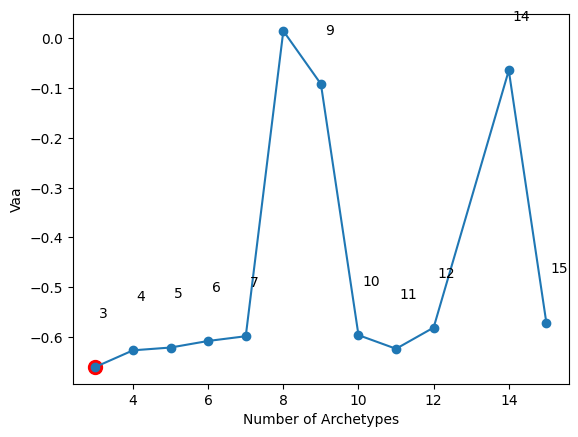

In [57]:
import glob

jsonFiles = glob.glob(r"results\Compendium_N3_N13_NoPC_NoGlom\Norm-Region\*.json")

losses = []

nIdx_archs = [3,4,5,6,7,8,9,10,11,12,14,15] #[5,6,7,8,9,10] # 


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in nIdx_archs:
    for j in jsonFiles:
        if f"K{n}_" in j:
            print("Calculating Vaa for K=", n)
            otu_dict = json.load(open(j, "r"))
            otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"]).to_numpy()
            archetypes = np.asarray(otu_dict["archetypes"])
            vaa = calc_vaa_2(X, archetypes, otu_aa)
            print(f"Vaa for K={n}:", vaa)
            arch_losses[n] = vaa


plt.plot(arch_losses.keys(), arch_losses.values(), marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Vaa")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(nIdx_archs):
    print(f"Arch {txt}: {arch_losses[txt]}")
    plt.annotate(f"{txt}", (nIdx_archs[i] + pad, arch_losses[txt] + pad))

# Plot the smallest loss in green
min_loss = min(arch_losses.values())
min_key = [key for key, value in arch_losses.items() if value == min_loss][0]
plt.scatter(min_key, min_loss, color="red", s=100)

plt.show()


In [17]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
def discriminant_score(X, labels, metric = "cos"): 
    centroids = {}
    for label in np.unique(labels):
        centroids[label] = np.mean(X[labels == label], axis=0)
    
    # For each sample, compute dCos = 1 - sample . centroid / ||sample|| * ||centroid||
    dMe = np.zeros(X.shape[0])
    DS = np.zeros(X.shape[0])

    if(metric == "cos"):
        metricFunc = lambda x, y: 1 - np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))
    elif (metric == "euc"):
        metricFunc = lambda x, y: np.linalg.norm(x - y)

    for i, f in enumerate(X):
        cc = centroids[labels[i]]
        dMe[i] = metricFunc(f, cc)

        
    for i, f in enumerate(X):
        if(dMe[i] == 0): 
            DS[i] = 1
        else: 
            aMe = 1.0 / abs(dMe[i])

            # Find dSum = sum of all dMe between a sample and each cluster centroid
            dSum = 0
            for label in np.unique(labels):
                dSum += metricFunc(f, centroids[label])
            DS[i] = aMe / dSum
    return DS

def calc_scores(otu, labels):
    """
    Calculate the silhouette score, Davies-Bouldin score, and Calinski-Harabasz score for the given data.
    otu: numpy array of shape (N, M)
    labels: numpy array of shape (N,)
    """
    silhouette = silhouette_score(otu, labels)
    db_score = davies_bouldin_score(otu, labels)
    ch_score = calinski_harabasz_score(otu, labels)
    
    # dcCos_scores = discriminant_score(otu.to_numpy(), labels, "cos")
    # dcCos_score = np.mean(dcCos_scores)
    # dcEuc_scores = discriminant_score(otu.to_numpy(), labels, "euc")
    # dcEuc_score = np.mean(dcEuc_scores)

    return {
        "silhouette": silhouette,
        "davies_bouldin": db_score,
        # "calinski_harabasz": ch_score,
        # "discriminant_cosine": dcCos_score,
        # "discriminant_euclidean": dcEuc_score
    }

100%|██████████| 10/10 [00:10<00:00,  1.02s/it]


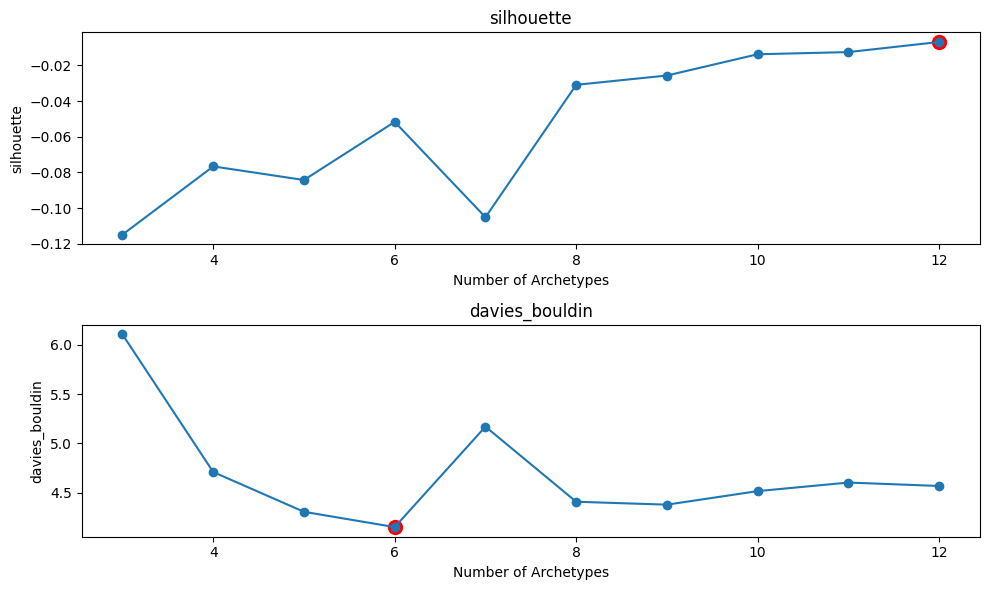

In [104]:
import glob
from tqdm import tqdm
jsonFiles = glob.glob(r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter-region7k\*.json")
filter_cols = ["region"]

losses = []

nIdx_archs = [3,4,5,6,7,8,9,10,11,12] #[5,6,7,8,9,10] #

projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in tqdm(nIdx_archs):
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])

            metadata = extract_metadata_compendium(otu_aa.index, tags, meta, projects, filter_cols)
            labels = metadata[filter_cols[0]].to_numpy()
            scores = calc_scores(otu_aa, labels)

            arch_losses[n] = scores
            # print(f"Scores for K={n}:", scores)


# Create a plot with 3 lines for each score in a different sub plots
numScores = len(arch_losses[nIdx_archs[0]].keys())
fig, axs = plt.subplots(numScores, 1, figsize=(10, 3*numScores))

for i, score in enumerate(arch_losses[nIdx_archs[0]].keys()):
    axs[i].plot(arch_losses.keys(), [arch_losses[n][score] for n in arch_losses.keys()], marker="o")
    axs[i].set_xlabel("Number of Archetypes")
    axs[i].set_ylabel(score)
    axs[i].set_title(score)

    # Highlight the best score in red
    best_func = max
    if(score == "davies_bouldin"): 
        best_func = min

    best_score = best_func([arch_losses[n][score] for n in arch_losses.keys()])
    best_key = [key for key, value in arch_losses.items() if value[score] == best_score][0]
    axs[i].scatter(best_key, best_score, color="red", s=100)

plt.tight_layout()


In [109]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp-sample_type\otu_AA_K6_1.0_None_jensenshannon.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)


reg_meta = extract_metadata_compendium(otu_aa.index, tags, meta, projects, ["sample_type"])
# Export the metadata to a tsv file
reg_meta.to_csv("datasets/compendium/sample-type_metadata.tsv", sep="\t")